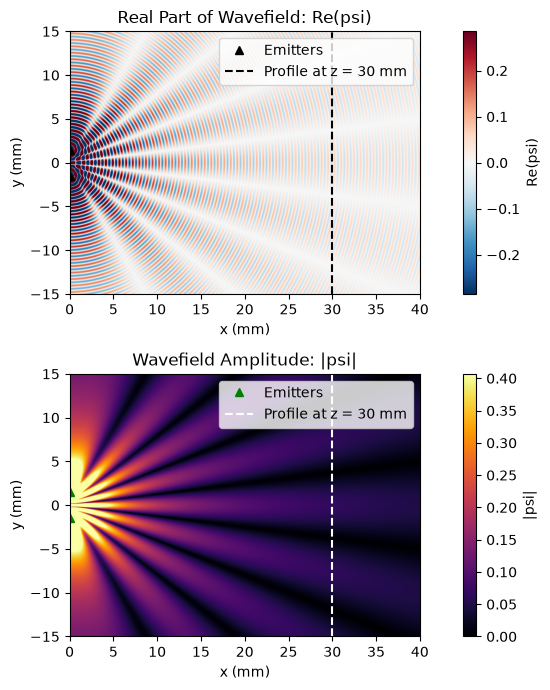

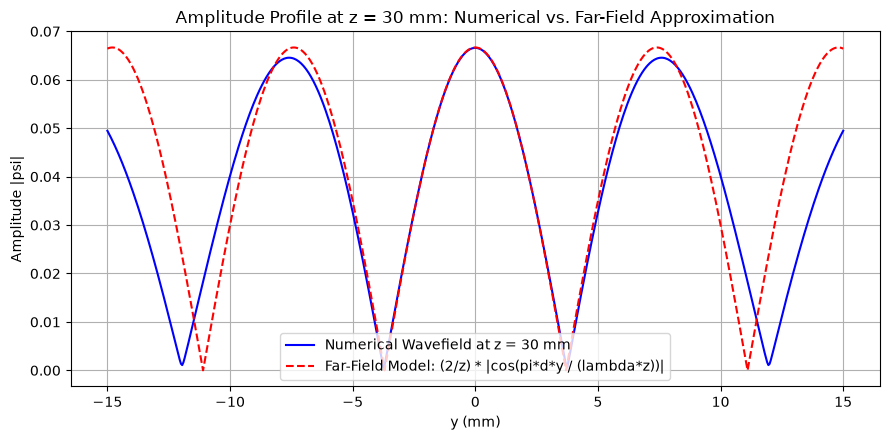

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Ultrasound and geometry parameters
c = 1480.0             # Speed of sound in water (m/s)
f = 2.0e6              # Frequency (2 MHz)
wl = (c / f) * 1e3     # Wavelength in mm (0.74 mm)
k = 2.0 * np.pi / wl   # Wavenumber (rad/mm)
d = 3.0                # Emitter separation (mm)

# 2. 2D grid setup (propagation in +x direction)
dx, dy = 0.05, 0.05
x = np.arange(dx, 40.0 + dx, dx)      # Propagation distance x (mm)
y = np.arange(-15.0, 15.0 + dy, dy)   # Transverse distance y (mm)
X, Y = np.meshgrid(x, y)

# 3. Superposition of two coherent spherical waves
r1 = np.sqrt(X**2 + (Y - d / 2.0)**2)  # Distance from top emitter
r2 = np.sqrt(X**2 + (Y + d / 2.0)**2)  # Distance from bottom emitter
psi = (1.0 / r1) * np.exp(1j * k * r1) + (1.0 / r2) * np.exp(1j * k * r2)

psi_real = np.real(psi)
psi_amp = np.abs(psi)

# 4. Plot 1: Wavefield Real Part and Amplitude images
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7))

vmax_real = np.percentile(np.abs(psi_real), 98)
im1 = ax1.imshow(psi_real, extent=[0, 40, -15, 15], cmap='RdBu_r', origin='lower',
                 vmin=-vmax_real, vmax=vmax_real, aspect='equal')
ax1.plot([0, 0], [d / 2.0, -d / 2.0], 'k^', markersize=6, label='Emitters')
ax1.axvline(30, color='k', linestyle='--', label='Profile at z = 30 mm')
ax1.set_xlabel('x (mm)')
ax1.set_ylabel('y (mm)')
ax1.set_title('Real Part of Wavefield: Re(psi)')
ax1.legend(loc='upper right')
fig.colorbar(im1, ax=ax1, label='Re(psi)')

vmax_amp = np.percentile(psi_amp, 98)
im2 = ax2.imshow(psi_amp, extent=[0, 40, -15, 15], cmap='inferno', origin='lower',
                 vmin=0, vmax=vmax_amp, aspect='equal')
ax2.plot([0, 0], [d / 2.0, -d / 2.0], 'g^', markersize=6, label='Emitters')
ax2.axvline(30, color='w', linestyle='--', label='Profile at z = 30 mm')
ax2.set_xlabel('x (mm)')
ax2.set_ylabel('y (mm)')
ax2.set_title('Wavefield Amplitude: |psi|')
ax2.legend(loc='upper right')
fig.colorbar(im2, ax=ax2, label='|psi|')

plt.tight_layout()
plt.savefig('Youngs_double_slit_exp_Nachiketh_wavefield.pdf')
plt.savefig('Youngs_double_slit_exp_Nachiketh_wavefield.png', dpi=150)
plt.show()

# 5. Plot 2: Amplitude profile at z = 30 mm and alternative far-field calculation
# Far-field Fraunhofer / Fourier approximation (valid for z >> d):
# Path difference Delta_r approx (d * y) / z
# |psi_far(z, y)| approx (2 / z) * |cos(pi * d * y / (lambda * z))|
z = 30.0
idx_z = np.argmin(np.abs(x - z))
profile_numerical = psi_amp[:, idx_z]
profile_farfield = (2.0 / z) * np.abs(np.cos(np.pi * d * y / (wl * z)))

plt.figure(figsize=(9, 4.5))
plt.plot(y, profile_numerical, 'b-', label='Numerical Wavefield at z = 30 mm')
plt.plot(y, profile_farfield, 'r--', label='Far-Field Model: (2/z) * |cos(pi*d*y / (lambda*z))|')
plt.xlabel('y (mm)')
plt.ylabel('Amplitude |psi|')
plt.title('Amplitude Profile at z = 30 mm: Numerical vs. Far-Field Approximation')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('Youngs_double_slit_exp_Nachiketh_profile.pdf')
plt.savefig('Youngs_double_slit_exp_Nachiketh_profile.png', dpi=150)
plt.show()
